In [1]:
import sys
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

import os
from pathlib import Path
import matplotlib.pyplot as plt
import yaml
import json

import yaml
config_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/config_files/setup.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config

from normalization import *
from scripts import *
from visualize import *

In [2]:
case, side, channel = "BreastMRI023", "L", 0
image, mask = load_task_inputs(case, side, channel, config["REFERENCE_OPTIONS"])
print("image:", image.GetSize(), image.GetPixelIDTypeAsString(), np.round(image.GetSpacing(), 4))
print("mask :", mask.GetSize(), mask.GetPixelIDTypeAsString())
print("same grid:", check_same_grid(image, mask))
try:
    check_same_grid(image, sitk.Shrink(mask, [2, 2, 1]))
except ValueError as error:
    print("a mismatched mask is rejected ->", error)

image: (448, 448, 192) 16-bit unsigned integer [0.8929 0.8929 1.    ]
mask : (448, 448, 192) 32-bit unsigned integer
same grid: True
a mismatched mask is rejected -> size differs: image (448, 448, 192) vs mask (224, 224, 192)


Intensity Normalization

$$ x' = s \cdot \operatorname{clip}\!\left(\frac{x - \mu}{\sigma},\, -k,\, k\right) $$

with $\mu$ and $\sigma$ the mean and standard deviation of **all voxels of the image**, $k$ = 3
(`removeOutliers`) and $s$ = 100 (`normalizeScale`). ITK's statistics use the sample standard deviation
(divisor $n-1$), so the same is done here. After normalization the values lie in [−300, 300], which is why
`voxelArrayShift = 300` makes them non-negative for the energy features (notebook 08).

In [3]:
ours = array_from_image(normalize_image(image, 100, 3))

# PyRadiomics' recipe: sitk.Normalize, then clip, then scale
itk_normalized = array_from_image(sitk.Normalize(image))
itk_recipe = np.clip(itk_normalized, -3, 3) * 100
print("normalized image dtype:", ours.dtype, "| range %.1f .. %.1f" % (ours.min(), ours.max()))
print("max |ours - SimpleITK recipe| =", np.abs(ours - itk_recipe).max())
raw = array_from_image(image).astype(float)
print("fraction of voxels clipped at +3 SD: %.4f %%" % (100 * (ours >= 300).mean()))

normalized image dtype: float64 | range -101.8 .. 300.0
max |ours - SimpleITK recipe| = 0.0
fraction of voxels clipped at +3 SD: 1.5557 %


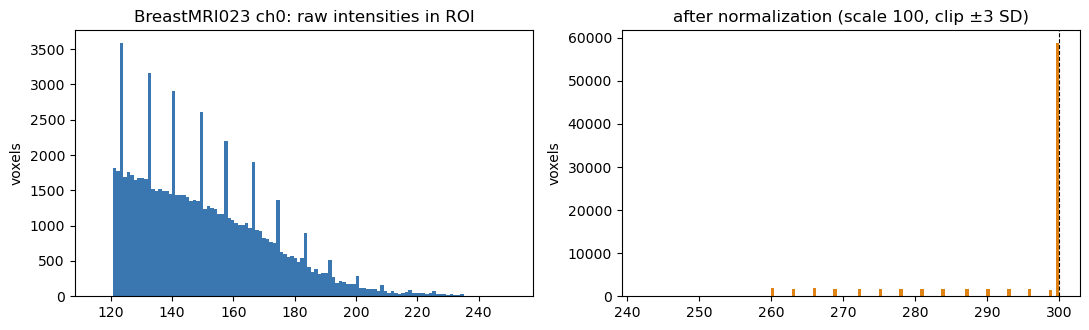

In [4]:
roi = array_from_image(mask) > 0
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(raw[roi], bins=120, color="#3a76af"); axes[0].set_title(f"{case} ch{channel}: raw intensities in ROI")
axes[1].hist(ours[roi], bins=120, color="#e08214"); axes[1].set_title("after normalization (scale 100, clip ±3 SD)")
axes[1].axvline(300, color="k", lw=0.8, ls="--")
for ax in axes:
    ax.set_ylabel("voxels")
fig.tight_layout()
fig.savefig(Path(config["FIGURE_DIR"]) / "normalization_histograms.png", dpi=110)
plt.show()

In [5]:
mask_array = array_from_image(mask)
statistics = sitk.LabelShapeStatisticsImageFilter()
statistics.Execute(mask)
print("bounding box (index, size) ours:", bounding_box_index_size(mask_array).tolist())
print("bounding box (index, size) sitk:", list(statistics.GetBoundingBox(1)))
print("bounding box (lower, upper)    :", bounding_box_lower_upper(mask_array).tolist())
print("ROI voxels:", check_roi(mask_array))

flat = np.zeros((5, 20, 20), np.uint8); flat[2, 5:15, 5:15] = 1          # a single-slice ROI
tiny = np.zeros((5, 20, 20), np.uint8); tiny[1:4, 1:4, 1:4] = 1          # 27 voxels
for name, test in (("flat", flat), ("tiny", tiny)):
    try:
        check_roi(test)
    except ValueError as error:
        print(f"{name:5s} ROI rejected ->", error)

bounding box (index, size) ours: [47, 226, 66, 106, 128, 95]
bounding box (index, size) sitk: [47, 226, 66, 106, 128, 95]
bounding box (lower, upper)    : [47, 152, 226, 353, 66, 160]
ROI voxels: 82489
flat  ROI rejected -> ROI has 2 dimension(s) with more than one voxel, 3 required
tiny  ROI rejected -> ROI has 27 voxels, more than 100 required


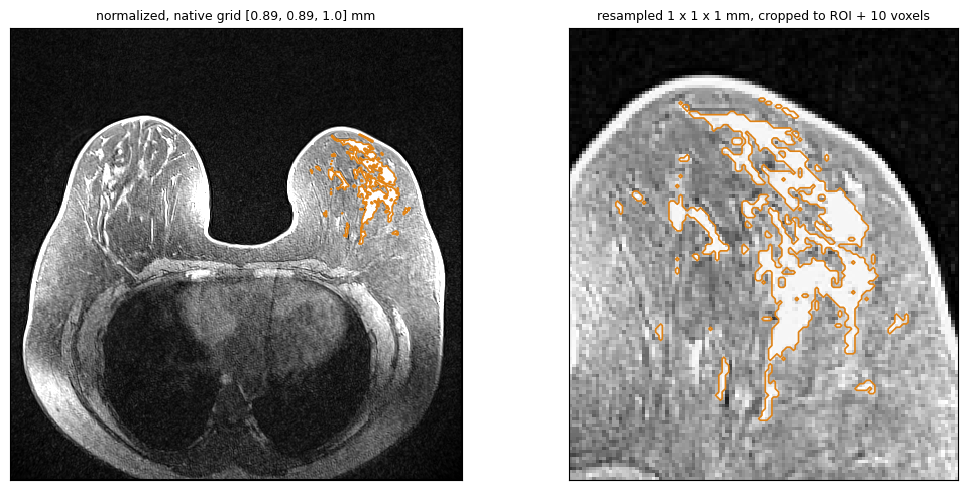

native grid voxels: 38535168 | resampled grid voxels: 1861704
ROI voxels native: 82489 (0.797 mm3 each) -> resampled: 65965 (1 mm3 each)


In [6]:
image, mask = load_task_inputs("BreastMRI023", "L", 0, config["REFERENCE_OPTIONS"])
result = preprocess(image, mask)
normalized = array_from_image(normalize_image(image, 100, 3))
mask_arr = array_from_image(mask) > 0

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
z = largest_slice_index(mask_arr, 0)
show_image_with_mask(axes[0], normalized, mask_arr, spacing_zyx(image), 0, z,
                     title="normalized, native grid %s mm" % np.round(image.GetSpacing(), 2).tolist())
z_r = largest_slice_index(result["mask_array"], 0)
show_image_with_mask(axes[1], result["image_array"], result["mask_array"], result["spacing_zyx"], 0, z_r,
                     title="resampled 1 x 1 x 1 mm, cropped to ROI + 10 voxels")
fig.tight_layout()
fig.savefig(Path(config["FIGURE_DIR"]) / "resampling.png", dpi=110)
plt.show()
print("native grid voxels:", np.prod(image.GetSize()), "| resampled grid voxels:", result["image_array"].size)
print("ROI voxels native: %d (%.3f mm3 each) -> resampled: %d (1 mm3 each)"
      % (result["diagnostics"]["original_voxels"], np.prod(image.GetSpacing()),
         result["diagnostics"]["interpolated_voxels"]))